# Small-band-count ablation — OxHyp / EuroCrops / BDForêt

A finer-grained companion to `random_band_ablation_results.ipynb`'s random-subset sweep, focused on
the **small-band regime**: random draws of just **3, 7, 10, 15, 20 bands** (3 seeds each), to see how
quickly performance climbs as a model goes from almost nothing to a modest subset.

Two phases:

- **Phase 1 — sanity check**: a **supervised, fully finetuned ViT-Small** (`vit_s`, random init,
  `freeze_backbone=false` — not a frozen linear probe) trained end-to-end on each band subset. Purpose:
  confirm these tiny subsets actually carry *increasing* information before spending compute re-running
  them through frozen pretrained encoders — a flat curve here would mean "no signal," not "linear
  probing is too weak to find it." Phase 1 confirmed a mostly-monotonic climb on every task checked.
- **Phase 2 — the real comparison**: the *exact same* (seed, size) band draws re-run through the 6
  frozen pretrained encoders (DOFA-B, DOFAv2-B, Copernicus-FM-B, Panopticon-B, CARL, UniverSat-B),
  linear probe, matching every other ablation in this benchmark.

**BNETD is deliberately excluded** — Phase 1 showed only a weak, flat signal there (mIoU essentially
unchanged from 7 through 20 bands), unlike the clean climbs on the other 3 tasks, so it wasn't worth
the Phase 2 compute. **BDForêt** (French forest-type segmentation, EnMAP, 12 classes) is included as a
second, genuinely different tree/forest task from BNETD's Ivorian forest-type map — added this session
alongside a fix to `BDForetDataset` (it was missing `band_indices` support entirely, blocking any
band-subset experiment on it).

**ViT-Small is not directly comparable to the other 6** — full end-to-end finetuning is a different
regime from frozen linear probing (it can adapt every weight to the tiny input, so it's shown as an
upper-bound/sanity-check reference, not an apples-to-apples competitor). The **Full** (all-bands)
reference for each of the 6 frozen encoders reuses their existing full-band baseline already on disk
elsewhere in this benchmark — not resubmitted here.

**Why logs, not `sacct`/checkpoint existence**: same rule as every other results notebook in this
benchmark — only the `Best ckpt path:` line `train.py` prints after `trainer.test()` finishes counts as
genuine completion.

**Metric note**: `oxhyperminerals_emit_l2a` uses `MultiLabelSegmentationModule` and logs
`test_MeanIoU`/`test_OverallAccuracy`, not `test_MulticlassJaccardIndex`/`test_MulticlassAccuracy` like
the single-label tasks. The parser tries both name variants per metric.

In [1]:
from __future__ import annotations

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Configuration

Mirrors the exact naming scheme used by `run_vit_s_small_band_ablation.sh` (Phase 1) /
`run_small_band_ablation.sh` / `run_small_band_universat.sh` (Phase 2). If any of those scripts'
naming changes, update it here too.

In [2]:
DISK_ROOT = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments/hsi-bench")

TASKS = ["oxhyperminerals_emit_l2a", "eurocrops", "bdforet"]
TASK_LABELS = {
    "oxhyperminerals_emit_l2a": "OxHyp",
    "eurocrops": "EuroCrops",
    "bdforet": "BDForet",
}
TASK_SENSOR = {
    "oxhyperminerals_emit_l2a": "emit",
    "eurocrops": "enmap",
    "bdforet": "enmap",
}

# The 5 wavelength-conditioned encoders, all frozen linear probe (Phase 2)
# -- plus vit_s, supervised fully-finetuned (Phase 1), shown as a reference,
# not a like-for-like competitor (see intro). UniverSat-B excluded (kicked
# out per request -- its results are no longer part of this comparison).
BACKBONES = ["dofa_b", "dofav2_b", "copernicus_fm_b", "panopticon_b", "carl"]
VIT_S_BACKBONE = "vit_s"
ALL_BACKBONES = BACKBONES + [VIT_S_BACKBONE]
BACKBONE_LABELS = {
    "dofa_b": "DOFA-B",
    "dofav2_b": "DOFAv2-B",
    "copernicus_fm_b": "Copernicus-FM-B",
    "panopticon_b": "Panopticon-B",
    "carl": "CARL",
    "universat_b": "UniverSat-B",
    "vit_s": "ViT-S (supervised, finetuned)",
}
WEIGHT_INIT = {
    "dofa_b": "dofa_pretrained",
    "dofav2_b": "dofav2_pretrained",
    "copernicus_fm_b": "copernicus_fm_pretrained",
    "panopticon_b": "panopticon_pretrained",
    "carl": "carl_pretrained",
    "vit_s": "random_init_finetune",
}
# Every backbone here is "linear" (frozen probe) except vit_s ("finetune").
PROTOCOL_MAP = {"vit_s": "finetune"}
DEFAULT_PROTOCOL = "linear"

DECODER = "mlp_fusion_head"
UNIVERSAT_BACKBONE = "universat_b"
UNIVERSAT_DECODER = "universat_conv_head"
UNIVERSAT_WEIGHT_INIT = "universat_pretrained"

SIZES = ["n3", "n7", "n10", "n15", "n20"]
SIZE_N_BANDS = {"n3": 3, "n7": 7, "n10": 10, "n15": 15, "n20": 20}
SEEDS = [0, 1, 2]

# Fixed categorical colors, one per CONDITION (full/n3/n7/n10/n15/n20) --
# same encoding as the other ablation notebooks in this benchmark (bar
# chart: x-axis clusters by backbone, bars within a cluster are the
# conditions). Bars are displayed ascending by band count with Full last
# (it's always the largest) -- see condition_spec() below -- so n20/full
# ends up adjacent even though slots 6/1 aren't consecutive in the palette's
# validated adjacent-pairlist; same accepted tradeoff already made in
# random_band_ablation_results.ipynb for the identical reason (this session
# has no Node.js to re-run the CVD validator against a reordered display).
CONDITION_LABELS = {"full": "Full", "n3": "N3", "n7": "N7", "n10": "N10", "n15": "N15", "n20": "N20"}
CONDITION_COLORS = {
    "full": "#2a78d6",   # blue
    "n3": "#eb6834",     # orange
    "n7": "#1baf7a",     # aqua
    "n10": "#eda100",    # yellow
    "n15": "#e87ba4",    # magenta
    "n20": "#008300",    # green
}
GRID_COLOR = "#e3e2dd"
TEXT_MUTED = "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2",
    "font.size": 10,
})

## Result extraction

In [3]:
_METRIC_PATTERNS = {
    "mIoU": [
        re.compile(r"test_MulticlassJaccardIndex\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_MeanIoU\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
    "accuracy": [
        re.compile(r"test_MulticlassAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_OverallAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
}


def parse_run_log(log_path: Path) -> dict | None:
    """Parse one .submitit/*/*_0_log.out file. Returns None if the run never
    reached trainer.test() (i.e. training didn\'t actually finish), regardless
    of what SLURM\'s own exit status says."""
    text = log_path.read_text(errors="ignore")
    if "Best ckpt path:" not in text:
        return None

    result: dict = {"log_path": str(log_path)}
    for name, patterns in _METRIC_PATTERNS.items():
        matches = None
        for pattern in patterns:
            found = pattern.findall(text)
            if found:
                matches = found
                break
        if not matches:
            return None
        result[name] = float(matches[-1])
    return result


def find_best_result(task_dir: Path) -> dict | None:
    """Find every completed run under task_dir and return the one with the
    highest test mIoU (there can legitimately be more than one multirun
    directory -- a rerun after a timeout/crash, or an accidental duplicate
    submission)."""
    log_files = sorted(task_dir.glob("multiruns/*/.submitit/*/*_0_log.out"))
    candidates = [parsed for f in log_files if (parsed := parse_run_log(f)) is not None]
    if not candidates:
        return None
    return max(candidates, key=lambda c: c["mIoU"])


def mlpfusion_task_dir(task: str, backbone: str, condition: str) -> Path:
    """Shared by the 5 pretrained encoders (protocol=linear) AND vit_s
    (protocol=finetune) -- both go through the same mlp_fusion_head /
    {task}_mlpfusion_linear experiment_setup, just different protocol/
    weight_init path segments."""
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_mlpfusion_linear"
    protocol = PROTOCOL_MAP.get(backbone, DEFAULT_PROTOCOL)
    weight_init = WEIGHT_INIT[backbone]
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / DECODER
        / backbone / protocol / weight_init
    )
    return base if condition == "full" else base / condition


def universat_task_dir(task: str, condition: str) -> Path:
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_convseg_linear"
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / UNIVERSAT_DECODER
        / UNIVERSAT_BACKBONE / "linear" / UNIVERSAT_WEIGHT_INIT
    )
    return base if condition == "full" else base / condition

## Build the long-format results table

One row per (task, backbone, size, seed) -- plus one "full" row per (task, backbone) reusing each
frozen encoder's existing full-band baseline (not resubmitted here). `n_bands` is `None` for the full
row (it's not part of the size sweep).

In [4]:
def build_rows(task_dir_fn, backbone: str, include_full: bool) -> list[dict]:
    rows = []
    for task in TASKS:
        if include_full:
            result = find_best_result(task_dir_fn(task, "full"))
            rows.append({
                "task": task, "backbone": backbone, "size": "full", "n_bands": None, "seed": None,
                "mIoU": result["mIoU"] if result else None,
                "accuracy": result["accuracy"] if result else None,
                "status": "done" if result else "missing/running",
            })
        for size in SIZES:
            for seed in SEEDS:
                condition = f"rand_{size}_s{seed}"
                result = find_best_result(task_dir_fn(task, condition))
                rows.append({
                    "task": task, "backbone": backbone, "size": size, "n_bands": SIZE_N_BANDS[size], "seed": seed,
                    "mIoU": result["mIoU"] if result else None,
                    "accuracy": result["accuracy"] if result else None,
                    "status": "done" if result else "missing/running",
                })
    return rows


def report_completion(df: pd.DataFrame, label: str):
    missing = df[df["status"] == "missing/running"]
    print(f"{len(df) - len(missing)} / {len(df)} {label} combinations completed.")
    if len(missing):
        print("Missing or still running:")
        display(missing[["task", "backbone", "size", "seed"]])


rows = []
for backbone in BACKBONES:
    if backbone == UNIVERSAT_BACKBONE:
        rows.extend(build_rows(universat_task_dir, backbone, include_full=True))
    else:
        task_dir_fn = lambda t, c, b=backbone: mlpfusion_task_dir(t, b, c)
        rows.extend(build_rows(task_dir_fn, backbone, include_full=True))
results_long = pd.DataFrame(rows)
report_completion(results_long, "Phase-2 (frozen encoder)")

vit_s_task_dir = lambda t, c: mlpfusion_task_dir(t, VIT_S_BACKBONE, c)
vit_s_rows = build_rows(vit_s_task_dir, VIT_S_BACKBONE, include_full=False)
vit_s_long = pd.DataFrame(vit_s_rows)
report_completion(vit_s_long, "Phase-1 (ViT-S)")

all_long = pd.concat([results_long, vit_s_long], ignore_index=True)

288 / 288 Phase-2 (frozen encoder) combinations completed.


45 / 45 Phase-1 (ViT-S) combinations completed.


## Shared bar-chart helper

One grouped bar chart per task: x-axis clusters by backbone (in `ALL_BACKBONES` order), bars within a
cluster are the band-count conditions (N3/N7/N10/N15/N20 + Full where available), ordered ascending by
band count with Full last. Each bar shows the mean across the 3 seeds with a min–max whisker, and its
value printed at the tip -- same convention as `random_band_ablation_results.ipynb` /
`wrong_wavelength_ablation_results.ipynb`. ViT-S has no Full bar (out of scope for Phase 1, see intro).

In [5]:
def condition_spec_for_task(df: pd.DataFrame, task: str, backbones: list[str]):
    # Which conditions actually have any data for this task, across the
    # given backbones -- "full" is absent for vit_s, so it's only included
    # when at least one backbone in this call has it. Sorted ascending by
    # band count, full last (see the CONDITION_COLORS comment).
    sub = df[(df.task == task) & (df.backbone.isin(backbones))]
    keys = [s for s in SIZES if sub[sub["size"] == s]["mIoU"].notna().any()]
    if sub[sub["size"] == "full"]["mIoU"].notna().any():
        keys.append("full")
    return keys


def get_condition_value(df: pd.DataFrame, task: str, backbone: str, key: str):
    # Returns (value, lower_err, upper_err) for one (task, backbone, condition-key).
    sub = df[(df.task == task) & (df.backbone == backbone) & (df["size"] == key)]["mIoU"].dropna()
    if not len(sub):
        return (np.nan, 0.0, 0.0)
    if key == "full":
        return (sub.iloc[0], 0.0, 0.0)
    m = sub.mean()
    return (m, m - sub.min(), sub.max() - m)


def plot_task_bars(df: pd.DataFrame, task: str, backbones=None):
    backbones = backbones or ALL_BACKBONES
    keys = condition_spec_for_task(df, task, backbones)
    n_cond = len(keys)
    n_back = len(backbones)
    bar_width = 0.8 / n_cond
    x = np.arange(n_back)

    per_cond = {}
    for key in keys:
        vals, los, his = [], [], []
        for b in backbones:
            m, lo, hi = get_condition_value(df, task, b, key)
            vals.append(m); los.append(lo); his.append(hi)
        per_cond[key] = (vals, los, his)

    y_max = max(0.05, np.nanmax([max(v) for (v, _, _) in per_cond.values() if len(v)]))
    label_pad = y_max * 0.02

    fig, ax = plt.subplots(figsize=(1.6 * n_back + 2.5, 4.8))
    for i, key in enumerate(keys):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals, los, his = per_cond[key]
        yerr = np.array([los, his])
        has_err = np.any(yerr > 0)
        ax.bar(
            x + offset, vals, width=bar_width * 0.92, color=CONDITION_COLORS[key], label=CONDITION_LABELS[key],
            yerr=yerr if has_err else None,
            capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
        )
        for xi, v, hi in zip(x + offset, vals, his):
            if np.isnan(v):
                continue
            top = v + (hi if has_err else 0.0)
            ax.text(
                xi, top + label_pad, f"{v:.2f}", ha="center", va="bottom",
                fontsize=6.5, rotation=90, color=TEXT_MUTED,
            )

    ax.set_xticks(x)
    ax.set_xticklabels([BACKBONE_LABELS[b] for b in backbones], rotation=15, ha="right")
    ax.set_ylabel("Test mIoU")
    ax.set_title(f"{TASK_LABELS[task]} — test mIoU vs. random band count")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.28)
    ax.legend(frameon=False, ncols=min(n_cond, 6), loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
    fig.tight_layout()
    return fig

# Results

Per task: mean test mIoU (whisker = observed min–max across the 3 seeds, value printed at each bar's
tip) per backbone, per band count. ViT-S is a different training regime from the other 6 (frozen
linear probe) -- see intro.

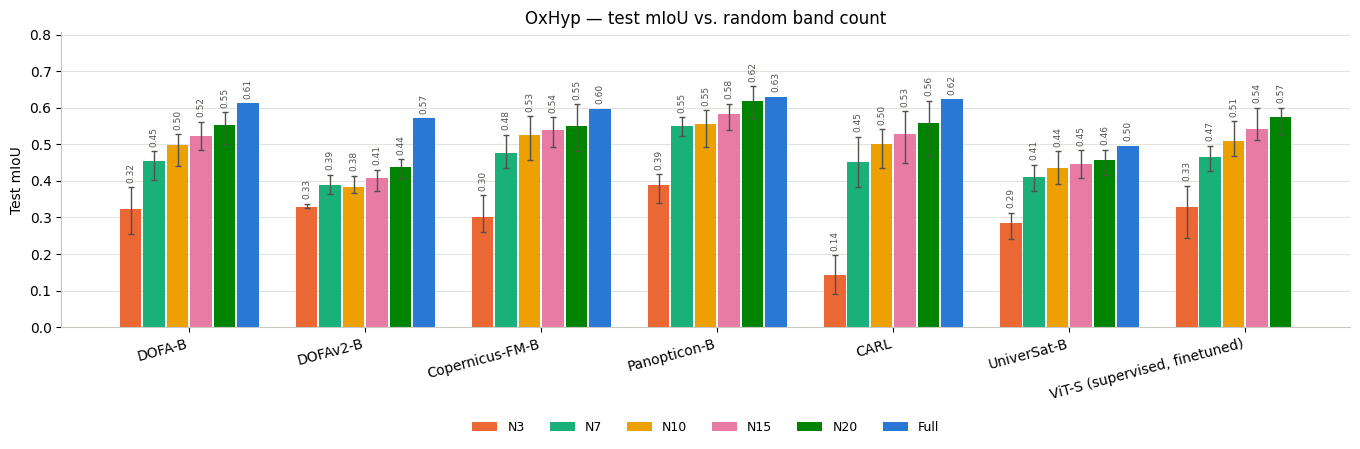

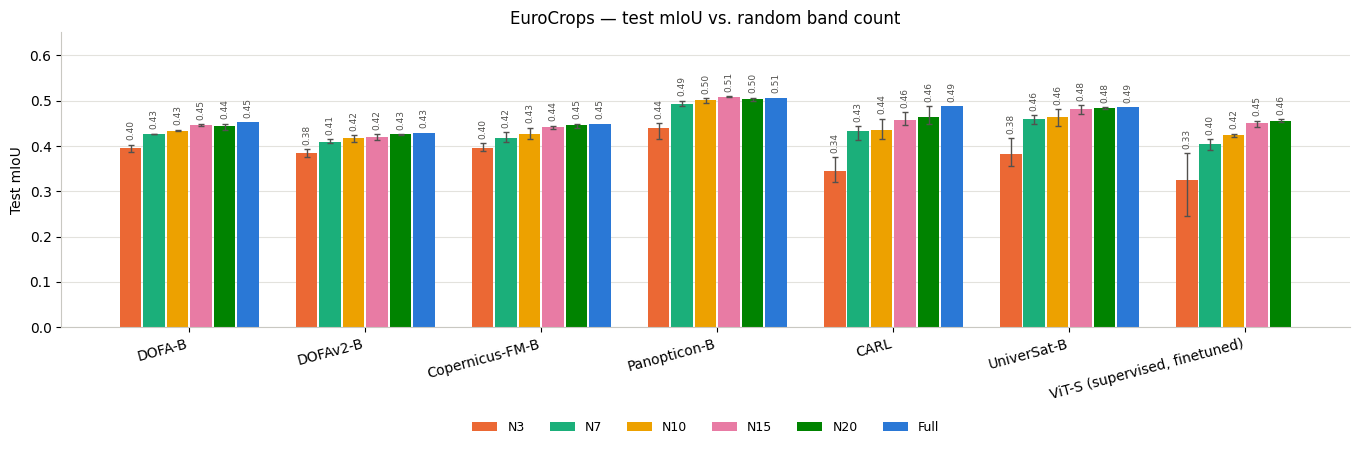

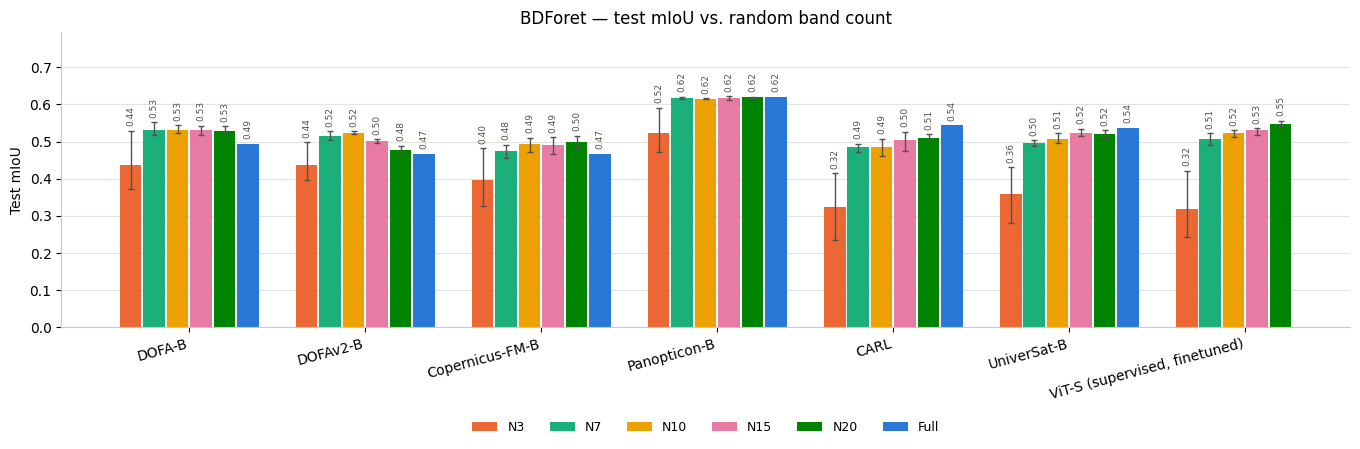

In [6]:
for task in TASKS:
    fig = plot_task_bars(all_long, task)
    plt.show()

### Detailed tables

In [7]:
def pivot_size(df: pd.DataFrame, size: str, backbones: list[str], metric: str = "mIoU") -> pd.DataFrame:
    subset = df[df["size"] == size].groupby(["task", "backbone"], as_index=False)[metric].mean()
    table = subset.pivot(index="backbone", columns="task", values=metric)
    row_order = [b for b in backbones if b in table.index]
    col_order = [t for t in TASKS if t in table.columns]
    table = table.reindex(index=row_order, columns=col_order)
    table.index = [BACKBONE_LABELS[b] for b in table.index]
    table.columns = [TASK_LABELS[t] for t in table.columns]
    return table


def style_table(df: pd.DataFrame, caption: str):
    return (
        df.style
        .format("{:.3f}", na_rep="\u2014")
        .highlight_max(axis=0, props="font-weight:bold;background-color:#e6f4ea;")
        .set_caption(caption)
    )


for size in SIZES + ["full"]:
    label = "Full" if size == "full" else f"{SIZE_N_BANDS[size]} bands"
    display(style_table(pivot_size(all_long, size, ALL_BACKBONES), f"{label} -- test mIoU"))

,OxHyp,EuroCrops,BDForet
DOFA-B,0.322,0.397,0.436
DOFAv2-B,0.329,0.385,0.436
Copernicus-FM-B,0.300,0.395,0.397
Panopticon-B,0.390,0.439,0.523
CARL,0.142,0.345,0.323
UniverSat-B,0.286,0.383,0.358
"ViT-S (supervised, finetuned)",0.328,0.325,0.318


,OxHyp,EuroCrops,BDForet
DOFA-B,0.454,0.427,0.531
DOFAv2-B,0.389,0.410,0.516
Copernicus-FM-B,0.477,0.417,0.476
Panopticon-B,0.550,0.493,0.617
CARL,0.452,0.433,0.486
UniverSat-B,0.411,0.459,0.497
"ViT-S (supervised, finetuned)",0.465,0.404,0.507


,OxHyp,EuroCrops,BDForet
DOFA-B,0.498,0.433,0.532
DOFAv2-B,0.384,0.417,0.523
Copernicus-FM-B,0.525,0.426,0.492
Panopticon-B,0.555,0.502,0.615
CARL,0.501,0.436,0.485
UniverSat-B,0.436,0.465,0.506
"ViT-S (supervised, finetuned)",0.510,0.424,0.523


,OxHyp,EuroCrops,BDForet
DOFA-B,0.522,0.446,0.531
DOFAv2-B,0.407,0.419,0.502
Copernicus-FM-B,0.540,0.442,0.491
Panopticon-B,0.582,0.509,0.617
CARL,0.528,0.457,0.504
UniverSat-B,0.445,0.481,0.524
"ViT-S (supervised, finetuned)",0.543,0.450,0.530


,OxHyp,EuroCrops,BDForet
DOFA-B,0.553,0.444,0.529
DOFAv2-B,0.438,0.426,0.478
Copernicus-FM-B,0.551,0.446,0.498
Panopticon-B,0.619,0.503,0.619
CARL,0.559,0.464,0.510
UniverSat-B,0.456,0.484,0.521
"ViT-S (supervised, finetuned)",0.575,0.456,0.547


,OxHyp,EuroCrops,BDForet
DOFA-B,0.612,0.452,0.495
DOFAv2-B,0.571,0.429,0.468
Copernicus-FM-B,0.597,0.449,0.468
Panopticon-B,0.630,0.507,0.621
CARL,0.624,0.488,0.544
UniverSat-B,0.496,0.485,0.537


## How close does 20 bands get to full-band?

For the 6 frozen encoders only (ViT-S has no full-band run -- out of scope for Phase 1, see intro):
mIoU at 20 random bands vs. that encoder's own full-band baseline, and the remaining gap.

In [8]:
def full_gap_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for task in TASKS:
        for backbone in BACKBONES:
            sub = df[(df.task == task) & (df.backbone == backbone)]
            full = sub[sub["size"] == "full"]["mIoU"]
            n20 = sub[sub["size"] == "n20"]["mIoU"].dropna()
            full_v = full.iloc[0] if len(full) else None
            rows.append({
                "task": TASK_LABELS[task],
                "backbone": BACKBONE_LABELS[backbone],
                "full_mIoU": full_v,
                "n20_mean_mIoU": n20.mean() if len(n20) else None,
                "gap_to_full": (full_v - n20.mean()) if full_v is not None and len(n20) else None,
                "pct_of_full": (100 * n20.mean() / full_v) if full_v else None,
            })
    return pd.DataFrame(rows)


gap_table = full_gap_table(results_long)
(
    gap_table.style
    .format({"full_mIoU": "{:.3f}", "n20_mean_mIoU": "{:.3f}", "gap_to_full": "{:.3f}", "pct_of_full": "{:.1f}%"}, na_rep="\u2014")
    .background_gradient(cmap="RdYlGn_r", subset=["gap_to_full"], vmin=0, vmax=0.15)
    .set_caption("20 random bands vs. that encoder's full-band baseline")
)

,task,backbone,full_mIoU,n20_mean_mIoU,gap_to_full,pct_of_full
0,OxHyp,DOFA-B,0.612,0.553,0.058,90.5%
1,OxHyp,DOFAv2-B,0.571,0.438,0.132,76.8%
2,OxHyp,Copernicus-FM-B,0.597,0.551,0.046,92.4%
3,OxHyp,Panopticon-B,0.630,0.619,0.011,98.2%
4,OxHyp,CARL,0.624,0.559,0.064,89.7%
5,OxHyp,UniverSat-B,0.496,0.456,0.040,91.9%
6,EuroCrops,DOFA-B,0.452,0.444,0.008,98.1%
7,EuroCrops,DOFAv2-B,0.429,0.426,0.004,99.2%
8,EuroCrops,Copernicus-FM-B,0.449,0.446,0.003,99.3%
9,EuroCrops,Panopticon-B,0.507,0.503,0.004,99.3%


## Single-seed comparison — the cleanest ViT-S continuation

The chart above averages all 3 seeds per condition, which hides each seed's own step-by-step shape.
Picking, per task, whichever single seed gave ViT-S the cleanest step-by-step climb (every step
3→7→10→15→20 strictly positive, no near-flat or negative step) -- **seed 0** for OxHyp and EuroCrops,
**seed 2** for BDForêt (see the per-seed table discussed above) -- this reruns the same bar chart as
before, but with every backbone's bars showing that *one specific run* per condition instead of a
3-seed mean, so what you're seeing is a single, real, directly-comparable band draw across every
encoder rather than an averaged trend line. No whiskers (nothing to average over anymore).

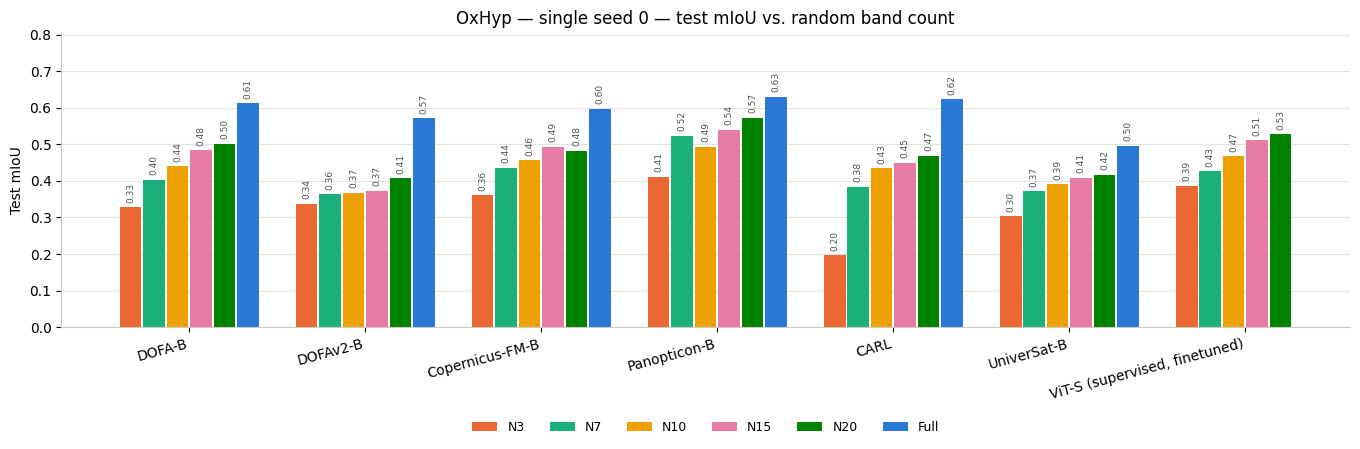

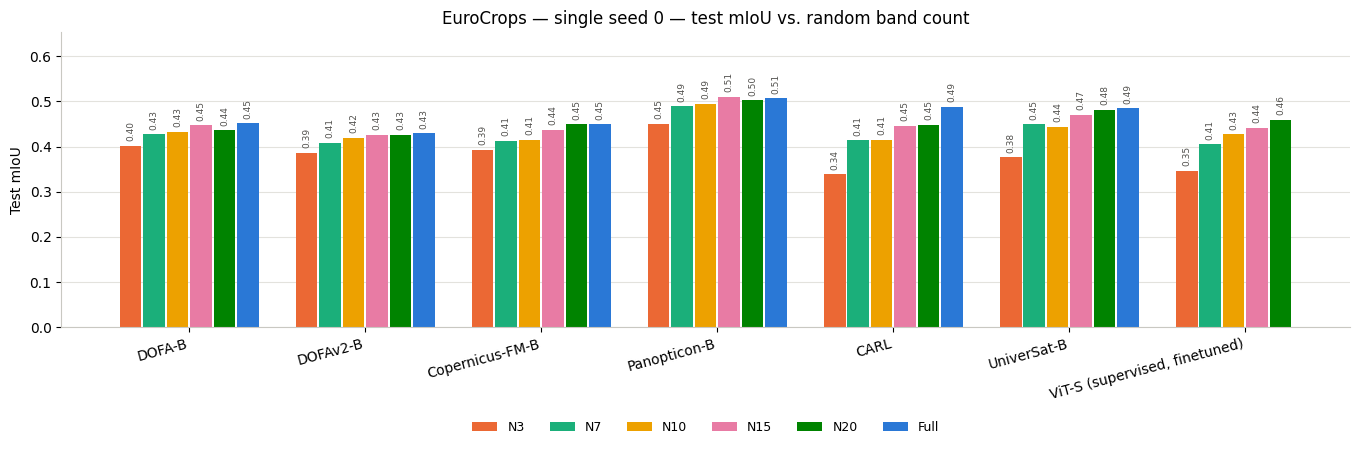

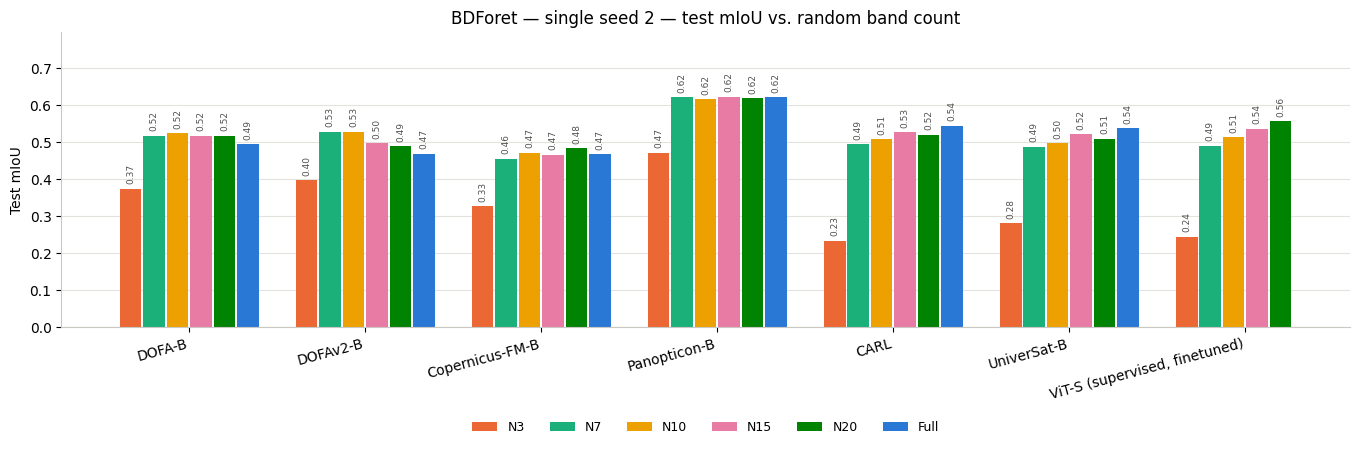

In [9]:
BEST_SEED_PER_TASK = {
    "oxhyperminerals_emit_l2a": 0,
    "eurocrops": 0,
    "bdforet": 2,
}


def get_condition_value_single_seed(df: pd.DataFrame, task: str, backbone: str, key: str, seed: int):
    if key == "full":
        v = df[(df.task == task) & (df.backbone == backbone) & (df["size"] == "full")]["mIoU"]
    else:
        v = df[(df.task == task) & (df.backbone == backbone) & (df["size"] == key) & (df.seed == seed)]["mIoU"]
    return v.iloc[0] if len(v) else np.nan


def plot_task_bars_single_seed(df: pd.DataFrame, task: str, seed: int, backbones=None):
    backbones = backbones or ALL_BACKBONES
    keys = condition_spec_for_task(df, task, backbones)
    n_cond = len(keys)
    n_back = len(backbones)
    bar_width = 0.8 / n_cond
    x = np.arange(n_back)

    per_cond = {key: [get_condition_value_single_seed(df, task, b, key, seed) for b in backbones] for key in keys}
    y_max = max(0.05, np.nanmax([np.nanmax(v) for v in per_cond.values()]))
    label_pad = y_max * 0.02

    fig, ax = plt.subplots(figsize=(1.6 * n_back + 2.5, 4.8))
    for i, key in enumerate(keys):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals = per_cond[key]
        ax.bar(x + offset, vals, width=bar_width * 0.92, color=CONDITION_COLORS[key], label=CONDITION_LABELS[key])
        for xi, v in zip(x + offset, vals):
            if np.isnan(v):
                continue
            ax.text(xi, v + label_pad, f"{v:.2f}", ha="center", va="bottom", fontsize=6.5, rotation=90, color=TEXT_MUTED)

    ax.set_xticks(x)
    ax.set_xticklabels([BACKBONE_LABELS[b] for b in backbones], rotation=15, ha="right")
    ax.set_ylabel("Test mIoU")
    ax.set_title(f"{TASK_LABELS[task]} — single seed {seed} — test mIoU vs. random band count")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.28)
    ax.legend(frameon=False, ncols=min(n_cond, 6), loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
    fig.tight_layout()
    return fig


for task in TASKS:
    fig = plot_task_bars_single_seed(all_long, task, BEST_SEED_PER_TASK[task])
    plt.show()

## Takeaways

**Panopticon-B dominates the small-band regime, clearly.** At just 3 random bands, Panopticon-B is
ahead of every other encoder on all 3 tasks — OxHyp 0.390 (next best DOFAv2-B 0.329), EuroCrops 0.439
(next best DOFA-B 0.397), and especially BDForêt 0.523 vs. 0.436 for the next best. It stays on top at
every subsequent size too, ending Phase 2 as the best frozen encoder at 20 bands on all 3 tasks
(OxHyp 0.619, EuroCrops 0.503, BDForêt 0.619). Whatever Panopticon-B's wavelength conditioning is
doing, it lets the model extract far more from a handful of arbitrary bands than any other encoder
here can manage.

**CARL is the clear opposite case at 3 bands** — 0.142 on OxHyp (vs. 0.30–0.39 for everyone else),
though it recovers sharply by 7 bands and is mid-pack from there on. Its normalization/conditioning
appears to need a few more channels before it has anything to work with.

**20 random bands already gets most encoders most of the way to full-band on OxHyp/EuroCrops** — 90–99%
of full-band mIoU for every encoder except DOFAv2-B on OxHyp (77%, the one real laggard in the gap
table). EuroCrops is even tighter: every encoder is within 1–5% of its own full-band score at just 20
of 202 bands.

**On BDForêt, several encoders actually *beat* their own full-band baseline at 20 bands** — DOFA-B
(105.3% → 0.529 vs. 0.495 full), DOFAv2-B (102.1%), and Copernicus-FM-B (106.6%) all score *higher*
with 20 well-drawn random bands than with the complete 202-band input. This mirrors the earlier
random-band-ablation finding that a scattered subset can outperform "more information" when the extra
bands add noise/redundancy rather than signal — apparently true even against the *full* spectrum, not
just against a same-sized semantic region, at least for this task.

**ViT-S (fully finetuned, no wavelength conditioning) never catches the best frozen encoder**, despite
being allowed to adapt every weight to the exact 3–20 bands it's given. At 20 bands it trails
Panopticon-B on every task (OxHyp 0.575 vs. 0.619, EuroCrops 0.456 vs. 0.503, BDForêt 0.547 vs. 0.619)
— consistent with the wrong-wavelength notebook's finding that these encoders' pretrained,
wavelength-aware representations are doing real work that 80 epochs of from-scratch supervised
finetuning on a comparatively small downstream dataset doesn't fully make up for. ViT-S does, however,
comfortably beat several of the *other* frozen encoders at small sizes (e.g. it beats CARL, UniverSat-B,
and Copernicus-FM-B at 3 bands on OxHyp) — so the frozen encoders' advantage isn't universal, just
concentrated in whichever one has the strongest wavelength conditioning for a given task.

**Caveat**: 3 seeds per size, same statistical-power caveat as every other ablation notebook in this
benchmark — enough to see the large, consistent effects above (Panopticon-B's lead, the BDForêt
full-band-beating results) but the shaded min–max bands in the main chart show real seed-to-seed spread
at 3 bands especially, which narrows quickly by 7–10 bands.